# OPSSAT-AD Dataset Anatomy

## Purpose

This notebook documents the structure and basic quality checks of `dataset.csv` and `segments.csv` for the project.

## What the Two Dataset Files Represent

`dataset.csv` is the fragment-level, tabular representation: each row describes one labelled telemetry fragment and contains its identifiers/metadata plus 18 provided handcrafted features (per the project data card). `segments.csv` is the raw time-series representation: each row is one timestamped telemetry value within a fragment.

The `segment` field identifies the fragment in both files, linking a `dataset.csv` feature row to its telemetry rows in `segments.csv`. In `segments.csv`, `timestamp` records when the observation was made and `value` is the telemetry measurement. The `channel` field identifies the telemetry channel. Exact timestamp conventions and the units/physical interpretation of `value` are ⚠️ Needs verification.

Both files carry fragment-related metadata, including `segment`, `channel` (in `dataset.csv` as well as `segments.csv`), `anomaly`, and `train`; `segments.csv` also includes `label` and `sampling`. These fields provide channel, anomaly-label, split, and sampling annotations at the represented row/fragment levels. The precise distinction and encoding semantics of `label` versus `anomaly`, and the units/meaning of `sampling`, are ⚠️ Needs verification. Feature columns in `dataset.csv` are the handcrafted fragment representation; meanings of individual feature columns are not inferred here.

## Field Roles

### `dataset.csv`

- **Label/anomaly:** `anomaly` is the anomaly-related label field; its exact encoding and semantics ⚠️ Needs verification.
- **Train/test split:** `train` records the published split membership (training versus test); the precise value mapping ⚠️ Needs verification.
- **Fragment identifier:** `segment` identifies the telemetry fragment.
- **Channel identifier:** `channel` identifies the source telemetry channel.
- **Handcrafted feature fields:** `duration`, `len`, `mean`, `var`, `std`, `kurtosis`, `skew`, `n_peaks`, `smooth10_n_peaks`, `smooth20_n_peaks`, `diff_peaks`, `diff2_peaks`, `diff_var`, `diff2_var`, `gaps_squared`, `len_weighted`, `var_div_duration`, and `var_div_len`. These are the 18 provided fragment-level handcrafted features identified in the project data card. This list is based on the documented feature count and the observed columns; meanings of individual features are not inferred here.
- **Other metadata:** `sampling` is present; its precise meaning/units ⚠️ Needs verification. The identifiers `segment` and `channel`, labels, split indicator, and `sampling` are kept distinct from the feature list above.

### `segments.csv`

- **Label/anomaly:** `label` and `anomaly` are label-related fields. Their exact relationship and encoding ⚠️ Needs verification; they are not assumed to be identical.
- **Train/test split:** `train` records split membership; the precise value mapping ⚠️ Needs verification.
- **Fragment identifier:** `segment` identifies the fragment.
- **Channel identifier:** `channel` identifies the telemetry channel.
- **Raw telemetry fields:** `timestamp` and `value` give the time and recorded telemetry value for each row. Timestamp conventions and physical units/interpretation ⚠️ Needs verification.
- **Other metadata:** `sampling` is present; its precise meaning/units ⚠️ Needs verification.

Identifiers such as `segment` and `channel` identify or group observations, while `train` describes the evaluation split. Treating them automatically as predictive inputs could let a model learn dataset organization or split membership instead of telemetry behaviour.

In [12]:
import os
import sys

print("Python version:", sys.version)
print("Current working directory:", os.getcwd())

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Current working directory: c:\Users\Mahesh Angadi\Desktop\SAT\explainable-satellite-telemetry-anomaly-detection\notebooks


In [13]:
import sys
print(sys.executable)
import pandas as pd


c:\Users\Mahesh Angadi\Desktop\SAT\explainable-satellite-telemetry-anomaly-detection\.venv\Scripts\python.exe


## File paths

The paths below point directly to the supplied files outside this Git repository.

In [14]:
DATASET_CSV_PATH = r"C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\dataset.csv"
SEGMENTS_CSV_PATH = r"C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\segments.csv"

print(f"dataset.csv: {DATASET_CSV_PATH}")
print(f"segments.csv: {SEGMENTS_CSV_PATH}")


dataset.csv: C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\dataset.csv
segments.csv: C:\Users\Mahesh Angadi\Desktop\SAT\OPSSAT-AD\segments.csv


## Loading the data

In [15]:
def load_csv_with_status(path, file_name):
    try:
        dataframe = pd.read_csv(path)
        print(f"{file_name} loaded successfully: True")
        return dataframe
    except Exception as error:
        print(f"{file_name} loaded successfully: False")
        print(f"{file_name} loading error: {error}")
        return None

dataset_df = load_csv_with_status(DATASET_CSV_PATH, "dataset.csv")
segments_df = load_csv_with_status(SEGMENTS_CSV_PATH, "segments.csv")


dataset.csv loaded successfully: True
segments.csv loaded successfully: True


## Dataset.csv inspection

In [16]:
if dataset_df is not None:
    print("Shape:", dataset_df.shape)
    print("\nExact column names:")
    print(dataset_df.columns.tolist())
    print("\nPandas dtypes:")
    print(dataset_df.dtypes)
    print("\nFirst 5 rows:")
    display(dataset_df.head())
    print("\nMissing-value counts:")
    print(dataset_df.isna().sum())


Shape: (2123, 23)

Exact column names:
['segment', 'anomaly', 'train', 'channel', 'sampling', 'duration', 'len', 'mean', 'var', 'std', 'kurtosis', 'skew', 'n_peaks', 'smooth10_n_peaks', 'smooth20_n_peaks', 'diff_peaks', 'diff2_peaks', 'diff_var', 'diff2_var', 'gaps_squared', 'len_weighted', 'var_div_duration', 'var_div_len']

Pandas dtypes:
segment               int64
anomaly               int64
train                 int64
channel                 str
sampling              int64
duration              int64
len                   int64
mean                float64
var                 float64
std                 float64
kurtosis            float64
skew                float64
n_peaks               int64
smooth10_n_peaks      int64
smooth20_n_peaks      int64
diff_peaks            int64
diff2_peaks           int64
diff_var            float64
diff2_var           float64
gaps_squared          int64
len_weighted          int64
var_div_duration    float64
var_div_len         float64
dtype: object

,segment,anomaly,train,channel,sampling,duration,len,mean,var,std,...,smooth10_n_peaks,smooth20_n_peaks,diff_peaks,diff2_peaks,diff_var,diff2_var,gaps_squared,len_weighted,var_div_duration,var_div_len
0,1,1,1,CADC0872,1,279,280,8.533143e-07,3.494283e-10,0.000019,...,3,2,4,6,1.271176e-10,2.960666e-10,279,280,1.252431e-12,1.247958e-12
1,2,1,1,CADC0872,1,476,477,-3.639396e-06,6.476485e-10,0.000025,...,1,1,5,8,1.489383e-12,3.004752e-12,476,477,1.360606e-12,1.357754e-12
2,3,1,1,CADC0872,1,594,595,1.170788e-05,5.592877e-10,0.000024,...,2,2,2,3,4.112280e-12,1.029918e-11,594,595,9.415618e-13,9.399794e-13
3,4,1,1,CADC0872,1,271,272,8.486808e-07,5.466024e-10,0.000023,...,2,2,3,6,2.475760e-11,6.240985e-11,271,272,2.016983e-12,2.009568e-12
4,5,0,0,CADC0872,1,256,257,1.058485e-05,5.279023e-10,0.000023,...,1,1,78,87,5.547101e-13,7.035422e-13,256,257,2.062118e-12,2.054094e-12



Missing-value counts:
segment             0
anomaly             0
train               0
channel             0
sampling            0
duration            0
len                 0
mean                0
var                 0
std                 0
kurtosis            0
skew                0
n_peaks             0
smooth10_n_peaks    0
smooth20_n_peaks    0
diff_peaks          0
diff2_peaks         0
diff_var            0
diff2_var           0
gaps_squared        0
len_weighted        0
var_div_duration    0
var_div_len         0
dtype: int64


## Segments.csv inspection

In [17]:
if segments_df is not None:
    print("Shape:", segments_df.shape)
    print("\nExact column names:")
    print(segments_df.columns.tolist())
    print("\nPandas dtypes:")
    print(segments_df.dtypes)
    print("\nFirst 5 rows:")
    display(segments_df.head())
    print("\nMissing-value counts:")
    print(segments_df.isna().sum())


Shape: (303493, 8)

Exact column names:
['channel', 'timestamp', 'value', 'label', 'sampling', 'anomaly', 'segment', 'train']

Pandas dtypes:
channel          str
timestamp        str
value        float64
label            str
sampling       int64
anomaly        int64
segment        int64
train          int64
dtype: object

First 5 rows:


,channel,timestamp,value,label,sampling,anomaly,segment,train
0,CADC0872,2022-06-01T23:42:54.000Z,-0.000021,anomaly,1,1,1,1
1,CADC0872,2022-06-01T23:42:55.000Z,-0.000021,anomaly,1,1,1,1
2,CADC0872,2022-06-01T23:42:56.000Z,-0.000021,anomaly,1,1,1,1
3,CADC0872,2022-06-01T23:42:57.000Z,-0.000021,anomaly,1,1,1,1
4,CADC0872,2022-06-01T23:42:58.000Z,-0.000021,anomaly,1,1,1,1



Missing-value counts:
channel      0
timestamp    0
value        0
label        0
sampling     0
anomaly      0
segment      0
train        0
dtype: int64


## Initial verification summary

In [18]:
print("dataset.csv loaded successfully:", dataset_df is not None)
print("segments.csv loaded successfully:", segments_df is not None)

if dataset_df is not None:
    print("dataset.csv shape:", dataset_df.shape)
if segments_df is not None:
    print("segments.csv shape:", segments_df.shape)

print("This notebook only records directly observed file structure and missing-value counts.")


dataset.csv loaded successfully: True
segments.csv loaded successfully: True
dataset.csv shape: (2123, 23)
segments.csv shape: (303493, 8)
This notebook only records directly observed file structure and missing-value counts.


## Basic Data-Quality Checks

These checks use the existing in-memory `dataset_df` and `segments_df`; they do not load or alter source files.

### Data types and missing values

The exact per-column dtypes are shown in the inspection sections above. The existing `isna()` outputs show 0 missing values in each of the 23 `dataset_df` columns and each of the 8 `segments_df` columns. The compact dtype summary below groups columns by dtype; the missing-value summary reuses the already reported results.

### Exact duplicate rows

An exact duplicate means every value in a row matches another row. Repeated `segment` identifiers alone are not counted as duplicate rows.

### Label and anomaly counts

Counts and percentages are reported separately for each available label-related field. This describes the observed values without recoding them or assuming `label` and `anomaly` have the same meaning; their semantic relationship ⚠️ Needs verification.

### Fragment sample counts

The number of rows per `segment` in `segments_df` is the observed telemetry sample count. The summary includes minimum, maximum, mean, median, and quartiles. These counts are compared with `dataset_df.len` by `segment`; this comparison does not change either field.

### Basic numerical ranges

The tables report only observed minimum and maximum values: raw telemetry `value` in `segments_df` and all numeric columns in `dataset_df`. They are descriptive ranges, not spacecraft operating limits.

In [19]:
# Use the existing dataframes; no CSV loading occurs in this cell.
for frame_name, frame in (("dataset_df", dataset_df), ("segments_df", segments_df)):
    print(f"\n{frame_name} dtype summary (column counts by dtype):")
    dtype_counts = frame.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("column_count")
    display(dtype_counts)

print("\nMissing-value summary (from the per-column isna() results above):")
display(pd.DataFrame({
    "dataframe": ["dataset_df", "segments_df"],
    "columns_with_missing_values": [0, 0],
    "total_missing_values": [0, 0],
    "columns_checked": [dataset_df.shape[1], segments_df.shape[1]],
}))

print("\nExact duplicate row counts:")
display(pd.DataFrame({
    "dataframe": ["dataset_df", "segments_df"],
    "exact_duplicate_rows": [int(dataset_df.duplicated().sum()), int(segments_df.duplicated().sum())],
}))

print("\nLabel/anomaly counts and percentages (computed independently per field):")
for frame_name, frame, fields in (("dataset_df", dataset_df, ("anomaly",)), ("segments_df", segments_df, ("label", "anomaly"))):
    for field in fields:
        counts = frame[field].value_counts(dropna=False, sort=False)
        summary = pd.DataFrame({"count": counts, "percent": (100 * counts / len(frame)).round(2)})
        summary.index.name = field
        print(f"{frame_name}.{field}")
        display(summary)

print("\nObserved telemetry samples per segment in segments_df:")
segment_lengths = segments_df.groupby("segment").size().rename("observed_samples")
length_summary = segment_lengths.describe(percentiles=[0.25, 0.50, 0.75]).to_frame("sample_count").T
length_summary["median"] = segment_lengths.median()
display(length_summary[["count", "min", "max", "mean", "median", "25%", "50%", "75%"]].round(2))

print("\nComparison of dataset_df.len with observed segment sample counts:")
length_comparison = dataset_df[["segment", "len"]].merge(
    segment_lengths.reset_index(), on="segment", how="outer", indicator=True
)
both_present = length_comparison["_merge"].eq("both")
length_matches = length_comparison["len"].eq(length_comparison["observed_samples"])
display(pd.DataFrame({
    "comparison": ["dataset_df rows with matching segment", "both present and lengths equal", "both present but lengths differ", "dataset_df segment without raw rows", "raw segment without dataset_df row"],
    "count": [int(both_present.sum()), int((both_present & length_matches).sum()), int((both_present & ~length_matches).sum()), int(length_comparison["_merge"].eq("left_only").sum()), int(length_comparison["_merge"].eq("right_only").sum())],
}))

print("\nObserved raw telemetry value range in segments_df:")
display(segments_df["value"].agg(["min", "max"]).to_frame("value").T)

print("\nObserved min/max for numeric columns in dataset_df:")
numeric_dataset = dataset_df.select_dtypes(include="number")
display(numeric_dataset.agg(["min", "max"]).T.rename(columns={"min": "minimum", "max": "maximum"}))


dataset_df dtype summary (column counts by dtype):


,column_count
dtype,
int64,13
float64,9
str,1



segments_df dtype summary (column counts by dtype):


,column_count
dtype,
int64,4
str,3
float64,1



Missing-value summary (from the per-column isna() results above):


...

,comparison,count
0,dataset_df rows with matching segment,2123
1,both present and lengths equal,2123
2,both present but lengths differ,0
3,dataset_df segment without raw rows,0
4,raw segment without dataset_df row,0



Observed raw telemetry value range in segments_df:


,min,max
value,-0.000101,1.5708



Observed min/max for numeric columns in dataset_df:


,minimum,maximum
segment,1.000000e+00,2123.000000
anomaly,0.000000e+00,1.000000
train,0.000000e+00,1.000000
sampling,1.000000e+00,5.000000
duration,3.500000e+01,1335.000000
len,8.000000e+00,1040.000000
mean,-3.833030e-05,1.118632
var,1.422763e-11,0.272480
std,3.771953e-06,0.521996
kurtosis,-1.858813e+00,31.201842


### Task 3 Interpretation

The existing inspection shows that both dataframes have populated dtype and per-column missing-value results, with no missing values observed in either file. The check output above records exact-row duplicates, observed label values, fragment sample counts, and numerical ranges. These are descriptions of the supplied tables; they do not establish why a label was assigned or whether a telemetry value is operationally safe.

## Representative Telemetry Fragment Plots

The cell below uses the already-loaded `segments_df` to plot up to three complete, distinct fragments from each observed `anomaly` category (0 and 1). It orders samples by timestamp and uses timestamps as the horizontal axis. The categories are labeled by their observed values because their exact semantic mapping ⚠️ Needs verification.


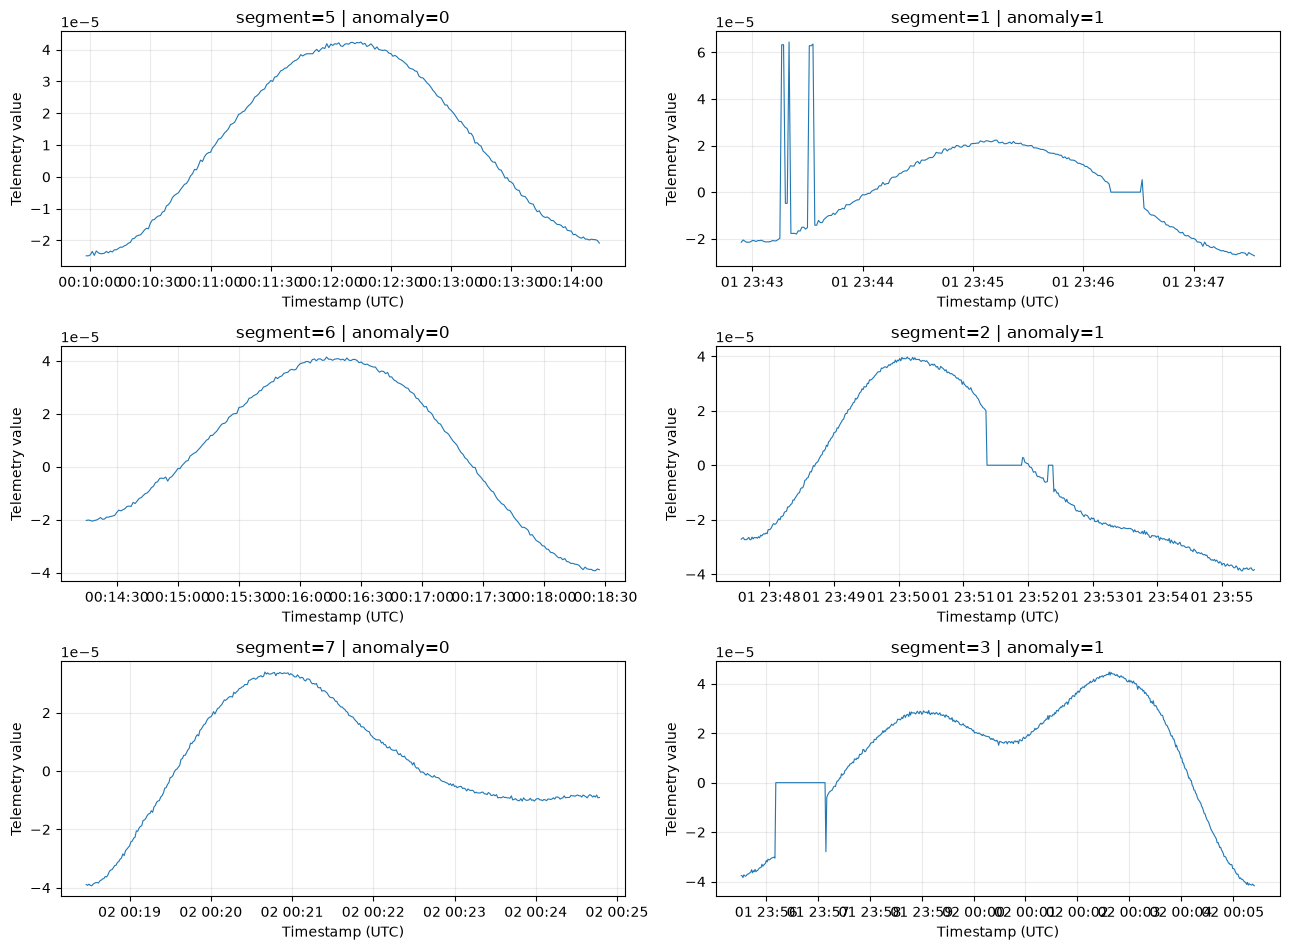

In [20]:
import matplotlib.pyplot as plt

# Select fragments whose observed anomaly value is consistent within the fragment.
segment_anomaly = segments_df.groupby("segment")["anomaly"].agg(["nunique", "first"])
selected_by_anomaly = {}
for anomaly_value in (0, 1):
    eligible_ids = segment_anomaly.index[
        segment_anomaly["nunique"].eq(1) & segment_anomaly["first"].eq(anomaly_value)
    ].tolist()
    selected_by_anomaly[anomaly_value] = eligible_ids[:3]
    if len(selected_by_anomaly[anomaly_value]) < 2:
        raise ValueError(
            f"Need at least two complete fragments with anomaly={anomaly_value}; "
            f"found {len(selected_by_anomaly[anomaly_value])}."
        )

n_examples = max(len(segment_ids) for segment_ids in selected_by_anomaly.values())
fig, axes = plt.subplots(n_examples, 2, figsize=(13, 3.2 * n_examples), squeeze=False)

for column, anomaly_value in enumerate((0, 1)):
    for row, segment_id in enumerate(selected_by_anomaly[anomaly_value]):
        fragment = segments_df.loc[segments_df["segment"].eq(segment_id)].copy()
        fragment["_plot_timestamp"] = pd.to_datetime(fragment["timestamp"], utc=True)
        fragment = fragment.sort_values("_plot_timestamp", kind="stable")

        ax = axes[row, column]
        ax.plot(fragment["_plot_timestamp"], fragment["value"], linewidth=0.8)
        ax.set_title(f"segment={segment_id} | anomaly={anomaly_value}")
        ax.set_xlabel("Timestamp (UTC)")
        ax.set_ylabel("Telemetry value")
        ax.grid(True, alpha=0.25)

    for row in range(len(selected_by_anomaly[anomaly_value]), n_examples):
        axes[row, column].set_visible(False)

fig.tight_layout()
plt.show()


The panels show complete telemetry-value traces over timestamp for distinct fragments in each observed anomaly category. They support visual comparison of the selected examples only; apparent differences do not establish a physical spacecraft fault or root cause.

### Visual Observation

The plotted traces make the within-fragment changes in telemetry value over time visible for the selected `anomaly=0` and `anomaly=1` examples. Any differences are descriptive observations about these examples and do not prove physical faults or root causes. ⚠️ Needs verification: exact semantic mapping of the anomaly encoding.


## Raw Telemetry vs Handcrafted Features

`segments.csv` stores telemetry as a sample-level temporal representation: each row contains a sample's `timestamp` and `value`, organized into fragments by `segment`. Keeping these timestamped samples preserves their temporal sequence.

`dataset.csv` provides a fragment-level handcrafted-feature representation. Each row describes a fragment and includes metadata, labels, split information, and the provided numerical features. Features such as `mean`, `var`, `std`, `kurtosis`, `skew`, and `n_peaks` summarize characteristics of a fragment; they do not preserve every sample in temporal order. These documented features are distinct from identifier, label, split, and other metadata fields, and this note does not designate all numeric columns as model inputs.

This distinction will be important when later comparing classical feature-based approaches with temporal modelling.